In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

candidates = [
    Path("../data/trudvsem_vacancies.parquet"),
    Path("data/trudvsem_vacancies.parquet"),
]
data_path = next(path for path in candidates if path.exists())
trudvsem_df = pd.read_parquet(data_path)

has_from = trudvsem_df["salary_from"].notna()
has_to = trudvsem_df["salary_to"].notna()

trudvsem_df["salary_shape"] = np.select(
    [has_from & has_to, has_from, has_to],
    ["Диапазон", "Только от", "Только до"],
    default="Зарплата не указана",
)

print("Уникальных вакансий:", trudvsem_df["id"].nunique())
print("Дублей ID:", trudvsem_df["id"].duplicated().sum())
display(trudvsem_df["salary_shape"].value_counts())
display(trudvsem_df["currency"].value_counts(dropna=False))

Уникальных вакансий: 1040
Дублей ID: 0


salary_shape
Диапазон    1040
Name: count, dtype: int64

currency
«руб.»    1040
Name: count, dtype: int64

In [2]:
trudvsem_df["currency_normalized"] = (
    trudvsem_df["currency"]
    .astype("string")
    .str.strip()
    .str.strip("«»\"'")
    .str.lower()
    .replace({
        "руб.": "RUR",
        "руб": "RUR",
        "rub": "RUR",
    })
)

trudvsem_df["salary_from"] = pd.to_numeric(
    trudvsem_df["salary_from"], errors="coerce"
)
trudvsem_df["salary_to"] = pd.to_numeric(
    trudvsem_df["salary_to"], errors="coerce"
)

training_trudvsem = trudvsem_df[
    trudvsem_df["currency_normalized"].eq("RUR")
    & trudvsem_df["salary_from"].notna()
    & trudvsem_df["salary_to"].notna()
].copy()

training_trudvsem["target_salary"] = (
    training_trudvsem["salary_from"] + training_trudvsem["salary_to"]
) / 2
training_trudvsem["range_width"] = (
    training_trudvsem["salary_to"] - training_trudvsem["salary_from"]
)

print("Строк для учебной выборки:", len(training_trudvsem))
print("Точные значения (границы совпадают):",
      training_trudvsem["range_width"].eq(0).sum())
display(training_trudvsem["target_salary"].describe().round(0))

Строк для учебной выборки: 1040
Точные значения (границы совпадают): 463


count      1040.0
mean      82536.0
std       60108.0
min           0.0
25%       40576.0
50%       63508.0
75%      105000.0
max      510000.0
Name: target_salary, dtype: float64

In [3]:
display(
    training_trudvsem.loc[
        (training_trudvsem["salary_from"] <= 0)
        | (training_trudvsem["salary_to"] <= 0)
        | (training_trudvsem["salary_from"] > training_trudvsem["salary_to"]),
        ["title", "salary_from", "salary_to", "target_salary", "region"]
    ]
)

,title,salary_from,salary_to,target_salary,region
37,Старший iOS-разработчик в MAX,0,0,0.0,Город Санкт-Петербург
38,Java-разработчик (Senior),343300,0,171650.0,Город Москва
84,Java-разработчик (Senior),343300,0,171650.0,Город Москва
220,Middle Data Scientist,0,0,0.0,Город Москва
221,Middle Fullstack QA-инженер (HR-платформа),0,0,0.0,Город Москва
224,"QA-инженер (Fullstack, автоматизация)",265800,0,132900.0,Город Москва
225,Системный аналитик,0,0,0.0,Город Москва
235,Senior/Middle+ Frontend разработчик (HR-платфо...,340000,0,170000.0,Город Москва
239,Руководитель группы разработки (Java Team Lead),343300,0,171650.0,Город Москва
298,Технический писатель,27093,0,13546.5,Город Москва


In [4]:
for column in ["salary_from", "salary_to"]:
    training_trudvsem[column] = training_trudvsem[column].replace(0, np.nan)

has_from = training_trudvsem["salary_from"].notna()
has_to = training_trudvsem["salary_to"].notna()

training_trudvsem["salary_shape"] = np.select(
    [has_from & has_to, has_from, has_to],
    ["Диапазон", "Только от", "Только до"],
    default="Зарплата не указана",
)

training_trudvsem["target_salary"] = np.where(
    has_from & has_to,
    (training_trudvsem["salary_from"] + training_trudvsem["salary_to"]) / 2,
    np.nan,
)

print(training_trudvsem["salary_shape"].value_counts())
print("Строк с полной зарплатной вилкой:",
      training_trudvsem["target_salary"].notna().sum())

salary_shape
Диапазон               987
Только от               32
Зарплата не указана     18
Только до                3
Name: count, dtype: int64
Строк с полной зарплатной вилкой: 987


In [5]:
invalid_ranges = training_trudvsem[
    training_trudvsem["salary_from"].lt(0)
    | training_trudvsem["salary_to"].lt(0)
    | training_trudvsem["salary_from"].gt(training_trudvsem["salary_to"])
]

print("Подозрительных диапазонов:", len(invalid_ranges))
display(
    invalid_ranges[
        ["title", "salary_from", "salary_to", "region"]
    ]
)

Подозрительных диапазонов: 0


,title,salary_from,salary_to,region


In [6]:
full_ranges = training_trudvsem[
    training_trudvsem["salary_shape"].eq("Диапазон")
].copy()

full_ranges["target_salary"] = (
    full_ranges["salary_from"] + full_ranges["salary_to"]
) / 2

display(full_ranges["target_salary"].describe().round(0))

count       987.0
mean      84479.0
std       59903.0
min       11176.0
25%       42266.0
50%       65000.0
75%      107500.0
max      510000.0
Name: target_salary, dtype: float64

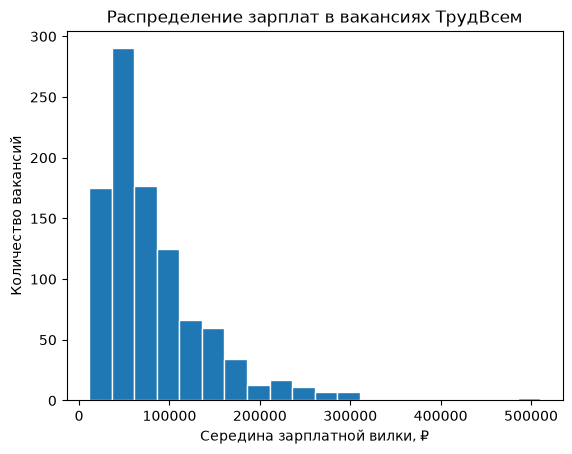

In [7]:
import matplotlib.pyplot as plt

full_ranges["target_salary"].plot.hist(bins=20, edgecolor="white")
plt.xlabel("Середина зарплатной вилки, ₽")
plt.ylabel("Количество вакансий")
plt.title("Распределение зарплат в вакансиях ТрудВсем")
plt.show()

In [8]:
display(
    full_ranges.nlargest(10, "target_salary")[
        ["title", "region", "salary_from", "salary_to", "target_salary"]
    ]
)

,title,region,salary_from,salary_to,target_salary
543,Доцент Факультета информационных технологий и ...,Город Москва,120000.0,900000.0,510000.0
542,Доцент Факультета информационных технологий и ...,Город Москва,106000.0,900000.0,503000.0
234,Ведущий инженер-программист (Team Lead) C++,Город Москва,350000.0,500000.0,425000.0
948,Геолог по ведению баз данных,Республика Бурятия,343000.0,343000.0,343000.0
564,Главный архитектор ИТ,Город Москва,300000.0,340000.0,320000.0
13,Старший разработчик 1С (Team Lead),Московская область,300000.0,300000.0,300000.0
217,Инженер-программист,Город Москва,250000.0,350000.0,300000.0
302,Системный архитектор,Город Москва,300000.0,300000.0,300000.0
306,IT-директор мобильного приложения,Омская область,100000.0,500000.0,300000.0
520,DevOps инженер,Город Москва,300000.0,300000.0,300000.0


In [9]:
print("Строк:", len(full_ranges))
print("\nКатегории:")
display(full_ranges["category"].value_counts(dropna=False))

print("\nРегионы:")
display(full_ranges["region"].value_counts().head(15))

Строк: 987

Категории:


category
Информационные технологии, телекоммуникации, связь                  466
Здравоохранение и социальное обеспечение                            107
Производство                                                         85
Образование, наука                                                   58
Продажи, закупки, снабжение, торговля                                26
Электроэнергетика                                                    23
ЖКХ, эксплуатация                                                    21
Административная работа, секретариат, АХО                            19
Транспорт, автобизнес, логистика, склад, ВЭД                         16
Машиностроение                                                       15
Пищевая промышленность                                               15
Банки, кредит, страхование, пенсионное обеспечение                   14
Строительство, ремонт, стройматериалы, недвижимость                  14
Государственная служба, некоммерческие организации     


Регионы:


region
Город Москва                        125
Город Санкт-Петербург                88
Свердловская область                 55
Республика Татарстан (Татарстан)     34
Самарская область                    34
Новосибирская область                33
Омская область                       31
Московская область                   29
Челябинская область                  27
Краснодарский край                   26
Ростовская область                   22
Пермский край                        20
Нижегородская область                20
Воронежская область                  19
Республика Башкортостан              16
Name: count, dtype: int64

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, median_absolute_error

ml_df = full_ranges.copy()

# Уберём дубли по названию и региону: одинаковые вакансии могут
# искусственно улучшить оценку на маленькой выборке.
ml_df = ml_df.drop_duplicates(subset=["title", "region"])

X = ml_df[["title", "region"]].fillna("")
y = ml_df["target_salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)


baseline = DummyRegressor(strategy="median")
baseline.fit(X_train[["title"]], y_train)
predictions = baseline.predict(X_test[["title"]])

print("Строк всего:", len(ml_df))
print("Train:", len(X_train), "Test:", len(X_test))
print("MAE:", round(mean_absolute_error(y_test, predictions)), "₽")
print("Median AE:", round(median_absolute_error(y_test, predictions)), "₽")
print("Медиана train:", round(y_train.median()), "₽")

Строк всего: 734
Train: 550 Test: 184
MAE: 41949 ₽
Median AE: 25000 ₽
Медиана train: 65000 ₽


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, median_absolute_error


features = ColumnTransformer(
    transformers=[
        (
            "title",
            TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 2),
                min_df=2,
                max_features=5000,
            ),
            "title",
        ),
        (
            "region",
            OneHotEncoder(handle_unknown="ignore"),
            ["region"],
        ),
    ],
    remainder="drop",
)

model = Pipeline(
    steps=[
        ("features", features),
        ("regressor", Ridge(alpha=10.0)),
    ]
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("MAE модели:", round(mean_absolute_error(y_test, predictions)), "₽")
print(
    "MAE baseline:",
    round(mean_absolute_error(y_test, baseline.predict(X_test[["title"]]))),
    "₽",
)

MAE модели: 36420 ₽
MAE baseline: 41949 ₽


In [12]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

baseline_scores = -cross_val_score(
    baseline, X[["title"]], y,
    cv=cv,
    scoring="neg_mean_absolute_error",
)

model_scores = -cross_val_score(
    model, X, y,
    cv=cv,
    scoring="neg_mean_absolute_error",
)

print("Baseline MAE по фолдам:", baseline_scores.round(0))
print("Модель MAE по фолдам:", model_scores.round(0))
print("Средняя MAE baseline:", round(baseline_scores.mean()), "₽")
print("Средняя MAE модели:", round(model_scores.mean()), "₽")

Baseline MAE по фолдам: [41807. 43025. 43157. 32364. 47355.]
Модель MAE по фолдам: [37630. 36765. 38461. 31164. 40761.]
Средняя MAE baseline: 41542 ₽
Средняя MAE модели: 36956 ₽


In [13]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone

def evaluate(name, estimator, X, y):
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_validate(
        clone(estimator),X,y,cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",              # средняя ошибка в рублях
            "mape": "neg_mean_absolute_percentage_error",  # средняя ошибка в процентах
        },
    )
    mae = -scores["test_mae"].mean()
    mape = -scores["test_mape"].mean() * 100
    print(f"{name:<26} ошибка {mae:>7,.0f} ₽   в процентах {mape:5.1f}%".replace(",", " "))
    return mae, mape

In [14]:
from sklearn.compose import TransformedTargetRegressor

# та же модель, но учится на логарифме зарплаты, а прогноз переводит обратно в рубли
log_model = TransformedTargetRegressor(
    regressor=model,
    func=np.log1p,
    inverse_func=np.expm1,
)

print("Все вакансии,", len(y), "строк\n")
evaluate("Бейзлайн (медиана)", baseline, X, y)
evaluate("Ridge", model, X, y)
evaluate("Ridge + логарифм", log_model, X, y)

Все вакансии, 734 строк

Бейзлайн (медиана)         ошибка  41 542 ₽   в процентах  52.0%
Ridge                      ошибка  36 956 ₽   в процентах  55.2%
Ridge + логарифм           ошибка  35 412 ₽   в процентах  44.5%


(np.float64(35412.12060626953), np.float64(44.54835649537699))

In [15]:
IT = "Информационные технологии, телекоммуникации, связь"

it_df = (
    full_ranges[full_ranges["category"].eq(IT)]
    .drop_duplicates(subset=["title", "region"])  # те же дубли убираем, как и раньше
)
X_it = it_df[["title", "region"]].fillna("")
y_it = it_df["target_salary"]

print("Только IT,", len(it_df), "строк, медиана", round(y_it.median()), "₽\n")
evaluate("Бейзлайн (медиана)", baseline, X_it, y_it)
evaluate("Ridge", model, X_it, y_it)
evaluate("Ridge + логарифм", log_model, X_it, y_it)

Только IT, 376 строк, медиана 75000 ₽

Бейзлайн (медиана)         ошибка  45 578 ₽   в процентах  55.7%
Ridge                      ошибка  44 302 ₽   в процентах  66.2%
Ridge + логарифм           ошибка  42 371 ₽   в процентах  52.5%


(np.float64(42370.77321339444), np.float64(52.52448354755466))

In [16]:
for alpha in [0.1, 0.3, 1, 3, 10]:
    tuned = TransformedTargetRegressor(
        regressor=clone(model).set_params(regressor__alpha=alpha),
        func=np.log1p,
        inverse_func=np.expm1,
    )
    evaluate(f"log, alpha={alpha}", tuned, X_it, y_it)

log  alpha=0.1             ошибка  48 002 ₽   в процентах  61.2%
log  alpha=0.3             ошибка  45 167 ₽   в процентах  57.0%
log  alpha=1               ошибка  43 317 ₽   в процентах  53.7%
log  alpha=3               ошибка  42 406 ₽   в процентах  52.3%
log  alpha=10              ошибка  42 371 ₽   в процентах  52.5%


In [17]:
import re

def grade(title: str) -> str:
    """Get level from title"""

    t = title.lower()
    if re.search(r"руковод|head|директор|cto|cio|team ?lead|тимлид|лид\b|lead", t):
        return "lead"
    if re.search(r"senior|сеньор|ведущ|старш|главн", t):
        return "senior"
    if re.search(r"middle|мидл", t):
        return "middle"
    if re.search(r"junior|джун|младш|стаж|intern|начинающ", t):
        return "junior"
    return "unknown"

it_df["grade"] = it_df["title"].map(grade)
display(it_df["grade"].value_counts())
display(it_df.groupby("grade")["target_salary"].median().sort_values().round(0))

grade
unknown    309
senior      37
lead        15
junior      12
middle       3
Name: count, dtype: int64

grade
junior      52500.0
senior      70000.0
unknown     70000.0
lead       165000.0
middle     200000.0
Name: target_salary, dtype: float64

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge

features_v2 = ColumnTransformer([
    ("title", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=5000), "title"),
    ("cats", OneHotEncoder(handle_unknown="ignore"), ["region", "grade"]),  # добавили grade
])

model_v2 = TransformedTargetRegressor(
    regressor=Pipeline([("features", features_v2), ("regressor", Ridge(alpha=3))]),
    func=np.log1p,
    inverse_func=np.expm1,
)

X_it2 = it_df[["title", "region", "grade"]].fillna("")
evaluate("Бейзлайн (медиана)", baseline, X_it2, y_it)
evaluate("log + alpha=3", log_model.set_params(regressor__regressor__alpha=3), X_it, y_it)
evaluate("log + alpha=3 + грейд", model_v2, X_it2, y_it)

Бейзлайн (медиана)         ошибка  45 578 ₽   в процентах  55.7%
log + alpha=3              ошибка  42 406 ₽   в процентах  52.3%
log + alpha=3 + грейд      ошибка  41 685 ₽   в процентах  51.6%


(np.float64(41684.78089374567), np.float64(51.57993912092225))